# 27 · The SSIM loss and the JND loss together

Notebook 26 trains the two best bodies on the JND loss instead of the SSIM loss. On the earlier sets the two failed in
different ways: the SSIM loss (`metrics.ssim_l1_loss`, 84% luma SSIM, 16% RGB L1) placed edges well and kept the
brightness, but left a faint grid of the upscaler's pixels and, on the fast q24, less of the fine detail; the JND loss
took most of that grid away and kept more detail, but let what it cannot see drift: edges a little less exact, and the
picture half a level brighter.

This notebook trains the sum, the SSIM loss + λ × the JND loss, so that the first holds edges and brightness while the
second takes out the grid:

- **The JND term** is notebook 26's loss: `PerceptualJNDLoss` with `helpers/jnd_settings.json`, so the line runs from
  the SSIM loss through the mixes to notebook 26's JND-loss runs under one definition of JND.
- **λ = 0.1, 0.3 and 1.** Section 2 measures how hard each loss pulls on the weights, the λ at which the two pull
  equally. A run is named by its λ: **mix 0.3** is the SSIM loss + 0.3 × the JND loss.
- **The recipe** is the shared one (`training.fit`): both bodies (told 24×2, fast q24), seeds 0 and 1, notebook 0's
  set, Adam from 1e-3, batch 32, the rate halved after 6 epochs without improvement, from random weights; the best epoch
  is the one with the lowest mix on the select split.

Each mix is set against the two runs it lies between, loaded from their files: the SSIM-loss runs of notebooks 22 and
24, and the JND-loss runs of notebook 26. The judges are notebook 26's: SSIM-Y, luma dB, JND and its MOS, and the two
that no loss here trains on, LPIPS and GMSD, all on notebook 0's validation split.

Needs: `22_upscale_qp_slice_models.ipynb`, `24_upscale_fast.ipynb` and `26_upscale_jnd_loss.ipynb` (their runs).

In [1]:
"""Settings."""

import json
import os
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn
from IPython.display import Image as Show, display
from PIL import Image
from torch.utils.data import DataLoader

os.environ["DATASETS_DIR"] = "/mnt/d/datasets"   # where the datasets are: set before helpers is imported

from helpers import degrade, judges, metrics, models, patches, sources, training
from helpers.training import DATA_DIR, DEVICE

NOTEBOOK = 27
RUN_DIR = training.CHECKPOINT_DIR / "mix_runs"                     # the mixed-loss trainings, saved every epoch
SAMPLES = training.SAMPLE_DIR / "27_mix" / "one_set"              # pictures, written to look at

QP_MAX = patches.QP_MAX
CONDITIONS = ("qp", "deblocked", "intra")
COLUMNS = patches.columns(CONDITIONS)
SEEDS = (0, 1)
LAMBDAS = {"mix 0.1": 0.1, "mix 0.3": 0.3, "mix 1": 1.0}          # mix λ: the SSIM loss + λ x the JND loss
LOSSES = ("SSIM loss", *LAMBDAS, "JND loss")                       # from no JND to only JND
# the two bodies: how to build each, and the run files of their SSIM-loss trainings (notebooks 22 and 24) and their
# JND-loss trainings (notebook 26)
BODIES = {
    "told 24x2": {"build": lambda: models.ToldLuma(len(COLUMNS), 24, 2, 3),
                  "ssim_runs": training.CHECKPOINT_DIR / "qp_runs" / "told_qp_frame_seed{seed}.pt",
                  "jnd_runs": training.CHECKPOINT_DIR / "jnd_runs" / "told_24x2_seed{seed}.pt"},
    "fast q24": {"build": lambda: models.FastLuma(width=24, stem=4, blocks=1, skip="truncated"),
                 "ssim_runs": training.CHECKPOINT_DIR / "fast_runs" / "q24_frozen_skip_seed{seed}.pt",
                 "jnd_runs": training.CHECKPOINT_DIR / "jnd_runs" / "fast_q24_seed{seed}.pt"},
}

manifest = training.load_manifest()
SCALE = manifest["scale"]
trim = training.trimmer(manifest)
RUN_DIR.mkdir(parents=True, exist_ok=True)
SAMPLES.mkdir(parents=True, exist_ok=True)
print("perceptual repo:", judges.PERCEPTUAL_DIR)

perceptual repo: /home/henrik/projects/perceptual


## 1. Data

Notebook 0's validation split, every patch with its slice QP / 51, loop filter and I frame, grouped by what it shows,
by line on P frames, and I frames.

In [2]:
val_set = patches.PatchPairs(DATA_DIR, "val", manifest, augment=False, told=CONDITIONS)
val_loader = DataLoader(val_set, batch_size=128)
files = manifest["splits"]["val"]
labels = {name: np.load(DATA_DIR / files[name]) for name in ("kind", "encoder", "intra", "qp")}
intra = labels["intra"].astype(bool)
GROUPS = {"all": np.ones(len(val_set), bool),
          **{f"{kind}s" if kind != "video" else kind: labels["kind"] == k for k, kind in enumerate(manifest["kinds"])},
          **{f"{encoder} P": (labels["encoder"] == e) & ~intra for e, encoder in enumerate(manifest["encoders"])},
          "I frames": intra}
print("val: " + ", ".join(f"{name} {mask.sum()}" for name, mask in GROUPS.items()))

val: all 24286, video 9416, screens 11199, photos 3671, x264 P 10385, nvenc P 10650, I frames 3251


## 2. Models and the losses

The JND term is notebook 26's loss, `helpers/jnd_settings.json`. Its masking is held constant under the gradient, so a
model cannot hide an error behind texture it adds.

In [3]:
def build(body, seed):
    torch.manual_seed(seed)
    return BODIES[body]["build"]().to(DEVICE)


class Bicubic(nn.Module):
    def forward(self, x, condition=None):
        return models.bicubic(x, SCALE)


jnd_term = judges.jnd_loss()   # notebook 26's loss: d / (d + 1) a picture, the batch's mean


def loss_of(loss):
    """The training loss of a row of LOSSES."""
    if loss == "SSIM loss":
        return metrics.ssim_l1_loss
    if loss == "JND loss":
        return jnd_term
    weight = LAMBDAS[loss]
    return lambda prediction, target: metrics.ssim_l1_loss(prediction, target) + weight * jnd_term(prediction, target)

### How hard each loss pulls

The two losses are on different scales, and what a loss adds to a training step is its gradient, not its value.
Below is the length of each loss's gradient on the model's weights, the mean over 16 training batches, for a model
before training and for the SSIM-loss run of seed 0 at its best epoch. Their ratio is the λ at which the two pull equally.

In [4]:
def grad_length(model, loss_fn, batches):
    """The length of a loss's gradient on the model's weights, the mean over `batches`."""
    model.train()
    lengths = []
    for (lr, condition), hr in batches:
        model.zero_grad(set_to_none=True)
        loss_fn(trim(model(lr, condition)), hr).backward()
        lengths.append(torch.sqrt(sum((p.grad ** 2).sum() for p in model.parameters() if p.grad is not None)).item())
    return float(np.mean(lengths))


torch.manual_seed(0)
train_loader, _ = training.loaders(DATA_DIR, manifest, training.BATCH_SIZE, 256, told=CONDITIONS,
                                   epoch_patches=16 * training.BATCH_SIZE)
batches = [((lr.to(DEVICE), condition.to(DEVICE)), hr.to(DEVICE)) for (lr, condition), hr in train_loader]
print("gradient length on the weights, the mean of 16 training batches")
for body in BODIES:
    for state in ("untrained", "SSIM loss, seed 0"):
        model = build(body, 0)
        if state != "untrained":
            model.load_state_dict(training.fitted_weights(Path(str(BODIES[body]["ssim_runs"]).format(seed=0))))
        ssim_pull, jnd_pull = grad_length(model, metrics.ssim_l1_loss, batches), grad_length(model, jnd_term, batches)
        print(f"  {body:<10} {state:<18} SSIM loss {ssim_pull:.3f}   JND loss {jnd_pull:.3f}   "
              f"equal at λ = {ssim_pull / jnd_pull:.2f}")

train  140795 patches
select   6982 patches, to choose the best epoch
gradient length on the weights, the mean of 16 training batches
  told 24x2  untrained          SSIM loss 0.554   JND loss 0.972   equal at λ = 0.57
  told 24x2  SSIM loss, seed 0  SSIM loss 0.241   JND loss 0.888   equal at λ = 0.27
  fast q24   untrained          SSIM loss 0.144   JND loss 0.417   equal at λ = 0.35
  fast q24   SSIM loss, seed 0  SSIM loss 0.247   JND loss 0.788   equal at λ = 0.31


## 3. Train

The SSIM-loss and JND-loss runs are loaded from their files (notebooks 22, 24 and 26); the three mixed runs of each body
and seed are trained from random weights with `training.fit` and saved every epoch in `checkpoints/mix_runs/`. A mixed
run keeps the epoch with the lowest mix on the select split, clamped as shown (an improvement is 1e-5, as for the JND
runs).

In [5]:
def run_file(body, loss, seed):
    if loss == "SSIM loss":
        return Path(str(BODIES[body]["ssim_runs"]).format(seed=seed))
    if loss == "JND loss":
        return Path(str(BODIES[body]["jnd_runs"]).format(seed=seed))
    return RUN_DIR / f"{body.replace(' ', '_')}_{loss.replace(' ', '_')}_seed{seed}.pt"


def recipe(loss):
    """`training.fit`'s loss and best-epoch settings for a row of LOSSES."""
    if loss == "SSIM loss":
        return {}
    key, fn = ("jnd" if loss == "JND loss" else "mix"), loss_of(loss)
    return dict(loss_fn=fn, select=key, scorer=lambda prediction, target: {key: fn(prediction.clamp(0, 1), target)},
                lower_is_better=True, min_improvement=1e-5)


def train(body, loss, seed):
    model = build(body, seed)
    settings = recipe(loss)
    history, best = training.fit(model, run_file(body, loss, seed), manifest, told=CONDITIONS, seed=seed, verbose=0,
                                 **settings)
    print(f"{body:<10} {loss:<10} seed {seed}: best epoch {best['epoch']:3} of {len(history):3}, "
          f"{settings.get('select', 'ssim')} {best['score']:.4f}")
    return model.eval(), history

In [6]:
trained, histories = {}, {}
for seed in SEEDS:
    for body in BODIES:
        for loss in LOSSES:
            trained[body, loss, seed], histories[body, loss, seed] = train(body, loss, seed)

train  140795 patches
select   6982 patches, to choose the best epoch
told 24x2  SSIM loss  seed 0: best epoch 122 of 134, ssim 0.8926
train  140795 patches
select   6982 patches, to choose the best epoch
told 24x2  mix 0.1    seed 0: best epoch 103 of 109, mix 0.1639
train  140795 patches
select   6982 patches, to choose the best epoch
told 24x2  mix 0.3    seed 0: best epoch  67 of  97, mix 0.3059
train  140795 patches
select   6982 patches, to choose the best epoch
told 24x2  mix 1      seed 0: best epoch  78 of  84, mix 0.8018
train  140795 patches
select   6982 patches, to choose the best epoch
told 24x2  JND loss   seed 0: best epoch  82 of  88, jnd 0.7086
train  140795 patches
select   6982 patches, to choose the best epoch
fast q24   SSIM loss  seed 0: best epoch 122 of 146, ssim 0.8789
train  140795 patches
select   6982 patches, to choose the best epoch
fast q24   mix 0.1    seed 0: best epoch  67 of  97, mix 0.1786
train  140795 patches
select   6982 patches, to choose the b

## 4. Scores

Every judge on every validation patch, the halo trimmed and the picture clamped as shown:

| judge | better | trained on by |
|---|---|---|
| SSIM-Y | higher | the SSIM loss (84% of it), and the mixes through it |
| luma dB | higher | the SSIM loss's L1, in part |
| JND (d under `helpers/jnd_settings.json`, CIEDE2000 for the tile means) | lower | the JND loss and the mixes' JND term (ΔE76 for the tile means) |
| MOS predicted from that d (BT.500, 1-5) | higher | the same, through d |
| LPIPS (AlexNet, v0.1) | lower | none |
| GMSD | lower | none |

A model's score is the mean of its two seeds. The networks add the same value to R, G and B, so U and V are the skip's
under every loss and are not shown.

In [7]:
judge_jnd, lpips = judges.jnd_judge(), judges.LPIPS().to(DEVICE)
JUDGES = {"ssim": ("SSIM-Y", 1), "y": ("luma dB", 1), "jnd": ("JND", -1), "mos": ("MOS", 1),
          "lpips": ("LPIPS", -1), "gmsd": ("GMSD", -1)}


@torch.no_grad()
def per_patch(model):
    """Every judge on every validation patch, as arrays."""
    model.eval()
    out = {key: [] for key in JUDGES}
    for (lr, condition), hr in val_loader:
        lr, condition, hr = lr.to(DEVICE), condition.to(DEVICE), hr.to(DEVICE)
        prediction = trim(model(lr, condition)).clamp(0, 1)
        each, rated = metrics.per_image(prediction, hr), judge_jnd.evaluate(prediction, hr)
        for key, value in (("ssim", each["ssim"]), ("y", each["y"]), ("jnd", rated["jnd"]), ("mos", rated["mos"]),
                           ("lpips", lpips(prediction, hr)), ("gmsd", judges.gmsd(prediction, hr))):
            out[key].append(value.float().cpu())
    return {key: torch.cat(value).numpy() for key, value in out.items()}


scores = {"bicubic": per_patch(Bicubic())}
for key, model in trained.items():
    scores[key] = per_patch(model)


def arm(body, loss, key):
    """A model's score on every patch, the mean of its seeds."""
    return np.mean([scores[body, loss, seed][key] for seed in SEEDS], axis=0)


def print_group(name):
    mask = GROUPS[name]
    print(f"{name} ({mask.sum()} patches)")
    print(f"  {'':<22}" + "".join(f"{label:>9}" for label, _ in JUDGES.values()))
    print(f"  {'bicubic':<22}" + "".join(f"{scores['bicubic'][key][mask].mean():9.4f}" for key in JUDGES))
    for body in BODIES:
        for loss in LOSSES:
            print(f"  {body + ', ' + loss:<22}" + "".join(f"{arm(body, loss, key)[mask].mean():9.4f}" for key in JUDGES))


for name in GROUPS:
    print_group(name)
    print()

print("how far apart the two seeds land, all patches")
for body in BODIES:
    for loss in LOSSES:
        gaps = [abs(scores[body, loss, 0][key].mean() - scores[body, loss, 1][key].mean()) for key in JUDGES]
        print(f"  {body + ', ' + loss:<22}" + "".join(f"{gap:9.4f}" for gap in gaps))

for (body, loss, seed), model in trained.items():   # SSIM-Y and dB for the table of every notebook (notebook 29)
    if loss in LAMBDAS:
        training.record(NOTEBOOK, f"{body}, {loss}" + (f", seed {seed}" if seed else ""),
                        training.val_scores(lambda lr, condition: model(lr, condition[:, COLUMNS]), manifest))

all (24286 patches)
                           SSIM-Y  luma dB      JND      MOS    LPIPS     GMSD
  bicubic                  0.8521  28.5815   6.1926   2.8306   0.2161   0.0983
  told 24x2, SSIM loss     0.8917  30.1736   4.5953   3.1601   0.1515   0.0759
  told 24x2, mix 0.1       0.8920  30.3473   4.5940   3.1836   0.1516   0.0753
  told 24x2, mix 0.3       0.8899  30.3114   4.6405   3.1818   0.1515   0.0762
  told 24x2, mix 1         0.8872  30.2493   4.7293   3.1732   0.1547   0.0773
  told 24x2, JND loss      0.8749  29.7599   4.8446   3.1465   0.1599   0.0826
  fast q24, SSIM loss      0.8758  29.2909   4.9797   3.0501   0.1663   0.0838
  fast q24, mix 0.1        0.8753  29.4235   4.9625   3.0673   0.1656   0.0833
  fast q24, mix 0.3        0.8742  29.4397   4.9833   3.0706   0.1670   0.0831
  fast q24, mix 1          0.8712  29.4040   5.0296   3.0694   0.1697   0.0839
  fast q24, JND loss       0.8628  29.1170   5.0697   3.0627   0.1691   0.0871

video (9416 patches)
          

Means hide how often: the share of patches on which each run beats the SSIM-loss run of its body, by judge (each the
mean of its two seeds; a tie counts for neither), and then by LPIPS in each group of patches.

In [8]:
print(f"{'better than the SSIM loss':<34}" + "".join(f"{label:>9}" for label, _ in JUDGES.values()))
for body in BODIES:
    for loss in LOSSES[1:]:
        cells = [np.mean(sign * (arm(body, loss, key) - arm(body, "SSIM loss", key)) > 0)
                 for key, (_, sign) in JUDGES.items()]
        print(f"  {body + ', ' + loss:<32}" + "".join(f"{cell:9.0%}" for cell in cells))
print()
names = ("all", *[name for name in GROUPS if name in ("screens", "photos", "video")])
print(f"{'by LPIPS, in each group':<34}" + "".join(f"{name:>20}" for name in names))
for body in BODIES:
    for loss in LOSSES[1:]:
        cells = [np.mean((arm(body, "SSIM loss", "lpips") - arm(body, loss, "lpips"))[GROUPS[name]] > 0) for name in names]
        print(f"  {body + ', ' + loss:<32}" + "".join(f"{cell:20.0%}" for cell in cells))

better than the SSIM loss            SSIM-Y  luma dB      JND      MOS    LPIPS     GMSD
  told 24x2, mix 0.1                    60%      74%      58%      58%      53%      62%
  told 24x2, mix 0.3                    29%      70%      54%      54%      54%      51%
  told 24x2, mix 1                      17%      58%      48%      48%      40%      46%
  told 24x2, JND loss                    6%      28%      40%      40%      30%      31%
  fast q24, mix 0.1                     46%      68%      57%      57%      55%      55%
  fast q24, mix 0.3                     33%      63%      54%      54%      48%      54%
  fast q24, mix 1                       18%      53%      49%      49%      39%      50%
  fast q24, JND loss                     6%      27%      45%      45%      43%      35%

by LPIPS, in each group                            all               video             screens              photos
  told 24x2, mix 0.1                               53%                 53%         

## 5. Pictures

Whole frames as the client sees them, made as notebook 26 makes them: the first validation clip of five groups of video,
1280×720 from its centre, frame 16 (a P frame), through the host's x264 line at its default 0.46 bits a pixel (a
640×360 stream) and starved at 0.5 Mbit/s. The models run on the whole stream frame with the client's 4 px of edge
read again around it, told the frame's slice QP, loop filter and type as the client tells them.

Each grid is the 240×135 window, at 2× with no smoothing, where the SSIM-loss run and the mix shown differ most (both
bodies summed): the truth (top) and bicubic (bottom) on the left, then the told 24×2 (top) and the fast q24 (bottom)
under the SSIM loss, the mix with the better validation LPIPS of the three, and the JND loss, all at seed 0. Picking
the mix by LPIPS makes LPIPS a judge it was chosen by; GMSD and the eye are not. Every whole frame of every run is
written to `data/samples/27_mix/one_set/frames/`, with what the stream did in `frames.json`.

the mix shown: told 24x2 mix 0.3, fast q24 mix 0.1 (the better validation LPIPS)
each grid: truth | told 24x2, SSIM loss | told 24x2, mix 0.3 | told 24x2, JND loss  /  bicubic | fast q24, SSIM loss | fast q24, mix 0.1 | fast q24, JND loss
video: desktop and software use, default (0.460 bpp): slice QP 0, window at (60, 472)


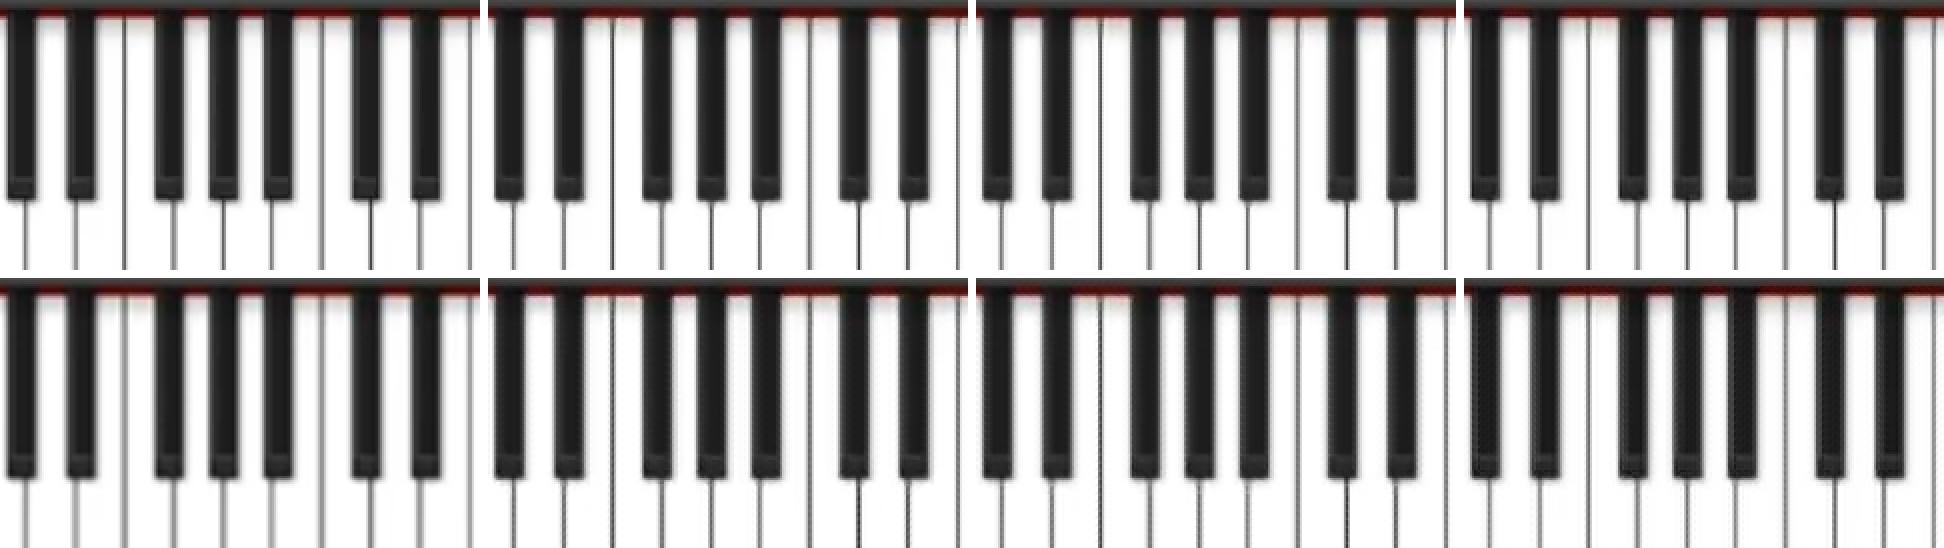

video: desktop and software use, 0.5mbps (0.091 bpp): slice QP 21, window at (780, 506)


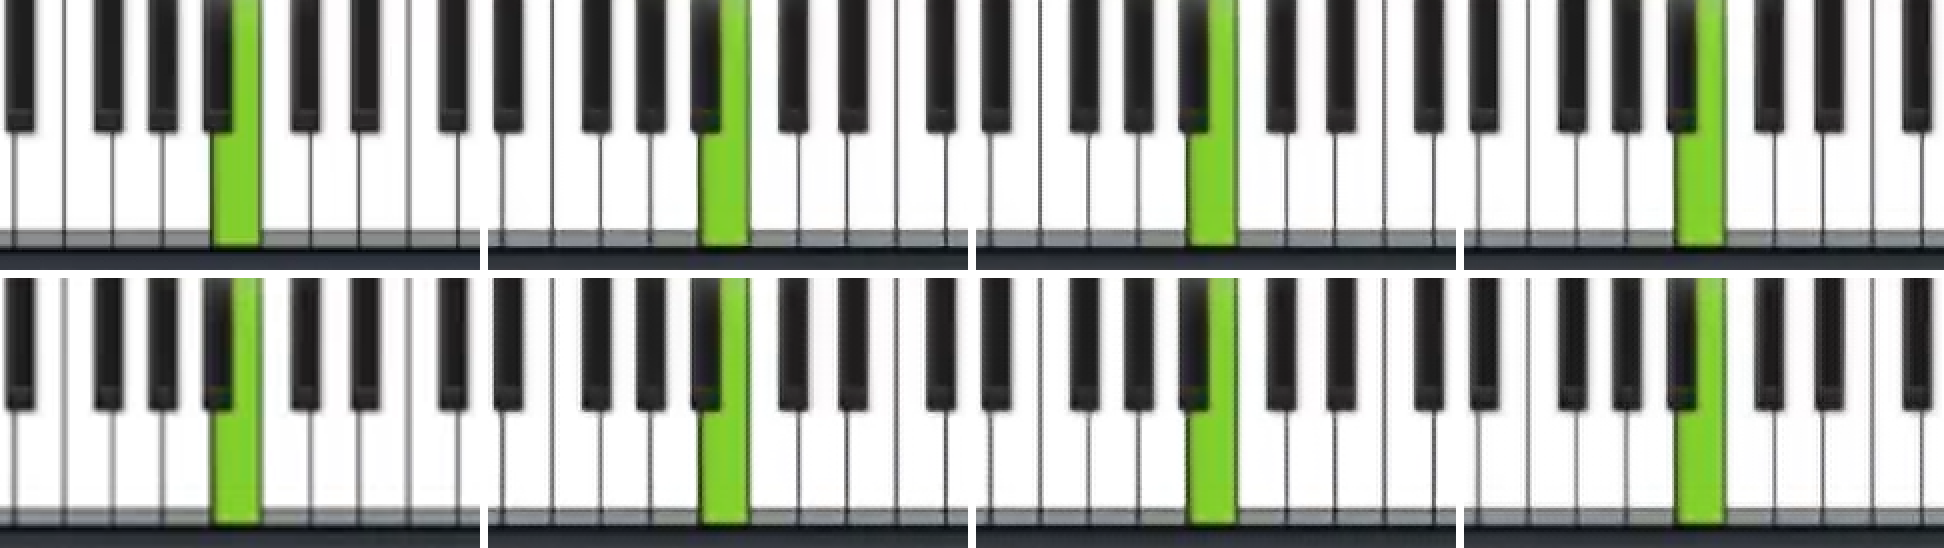

video: creative software, default (0.460 bpp): slice QP 12, window at (540, 371)


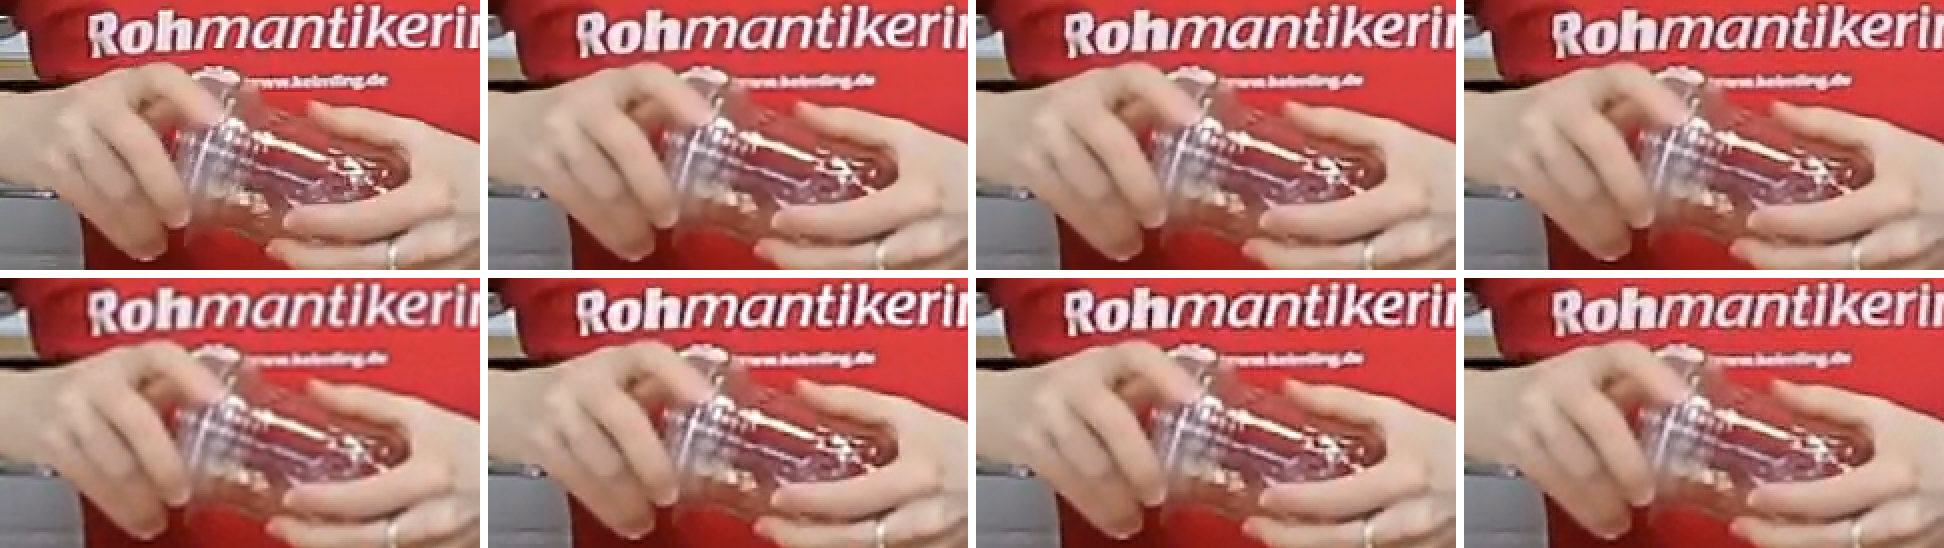

video: creative software, 0.5mbps (0.087 bpp): slice QP 28, window at (540, 371)


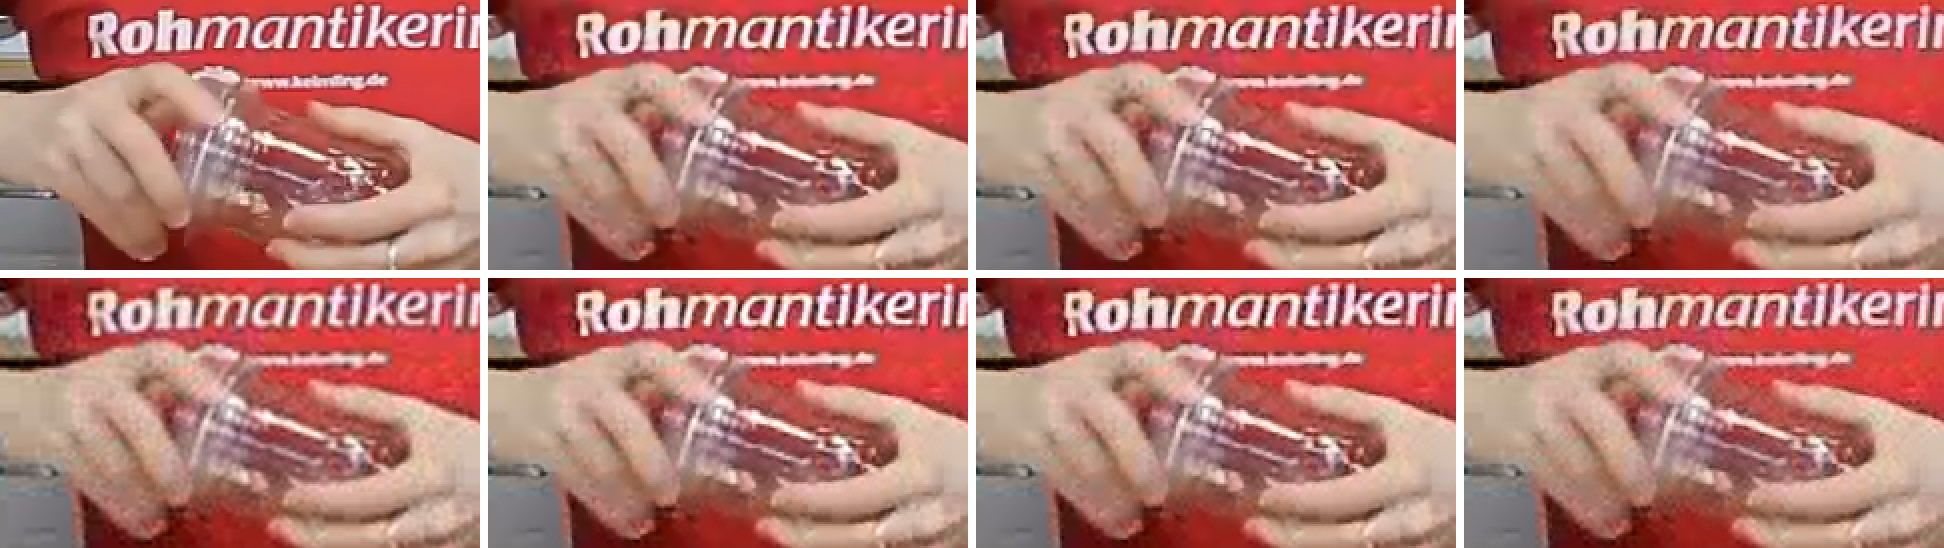

video: pc games, default (0.460 bpp): slice QP 4, window at (660, 168)


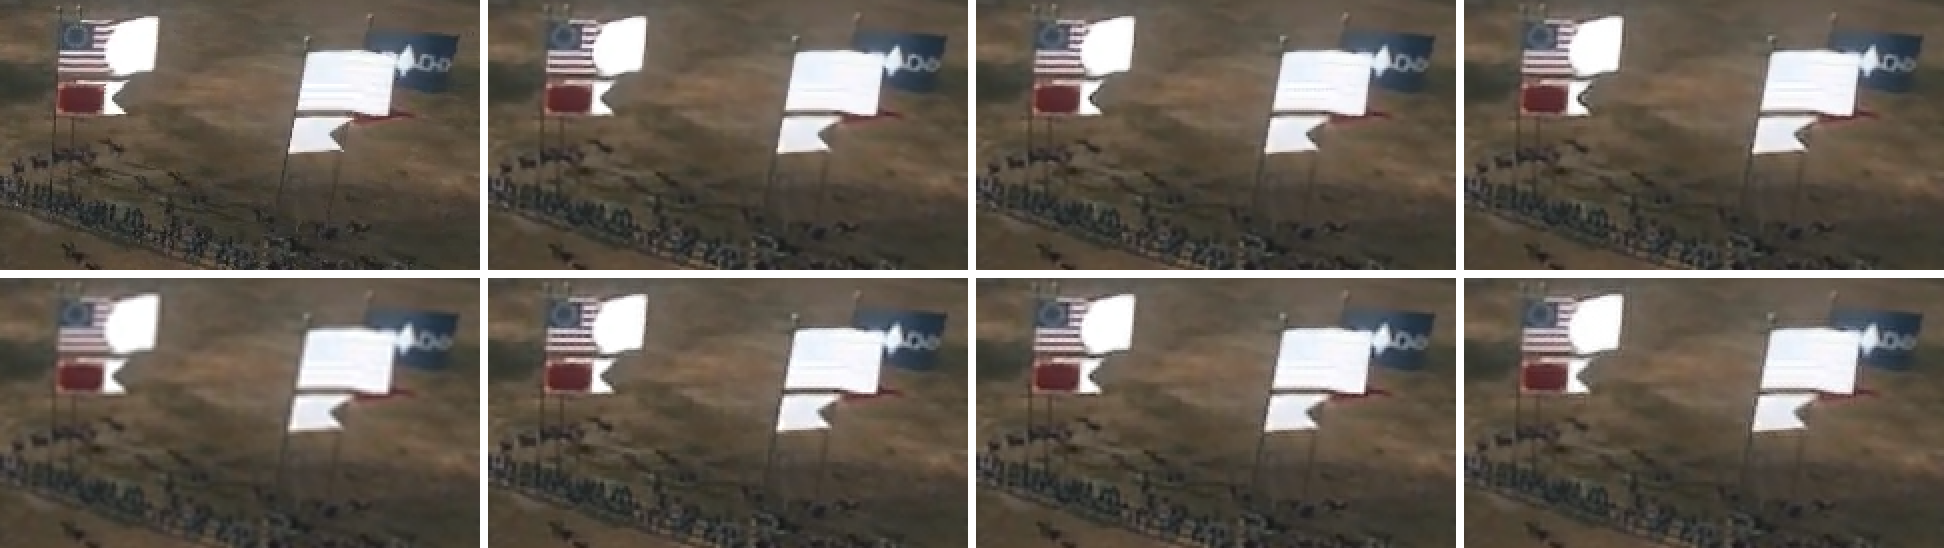

video: pc games, 0.5mbps (0.072 bpp): slice QP 18, window at (660, 168)


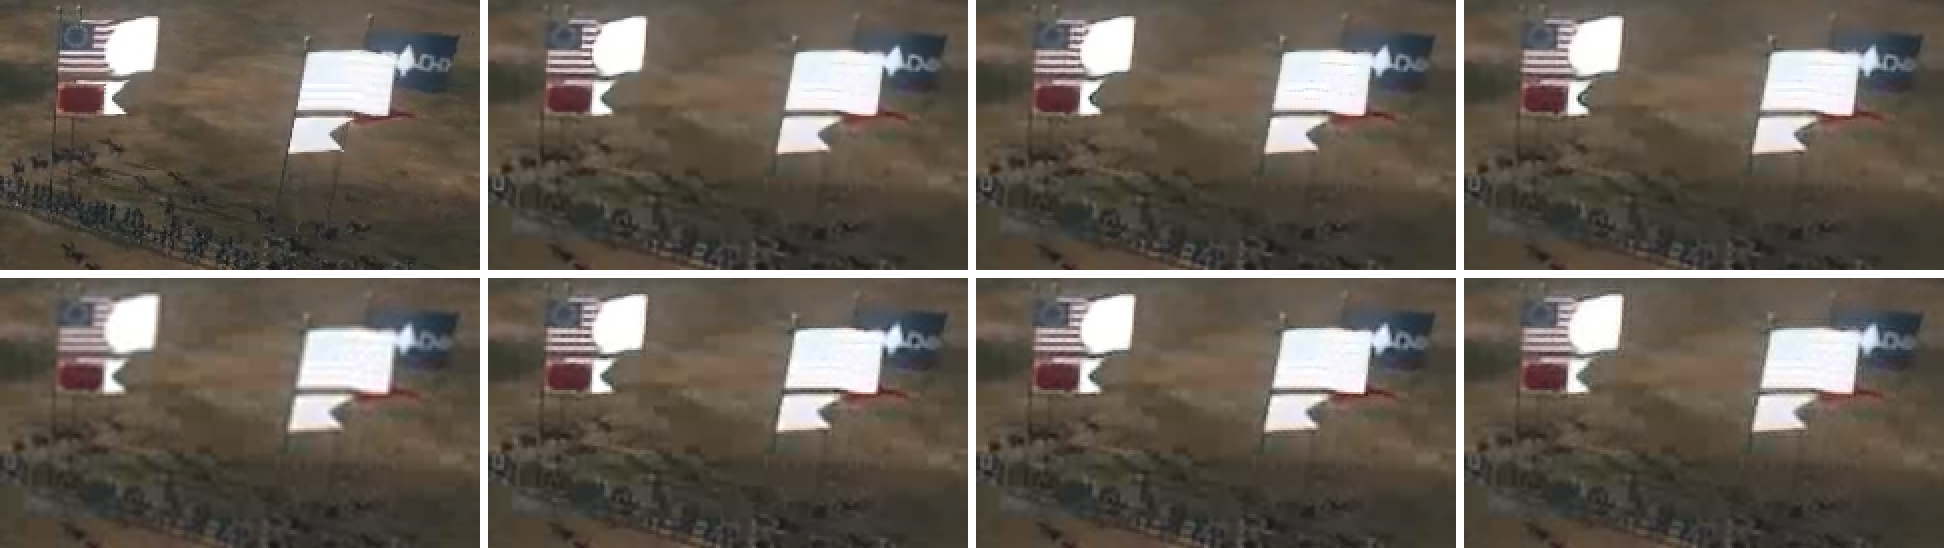

video: animation, default (0.460 bpp): slice QP 0, window at (360, 405)


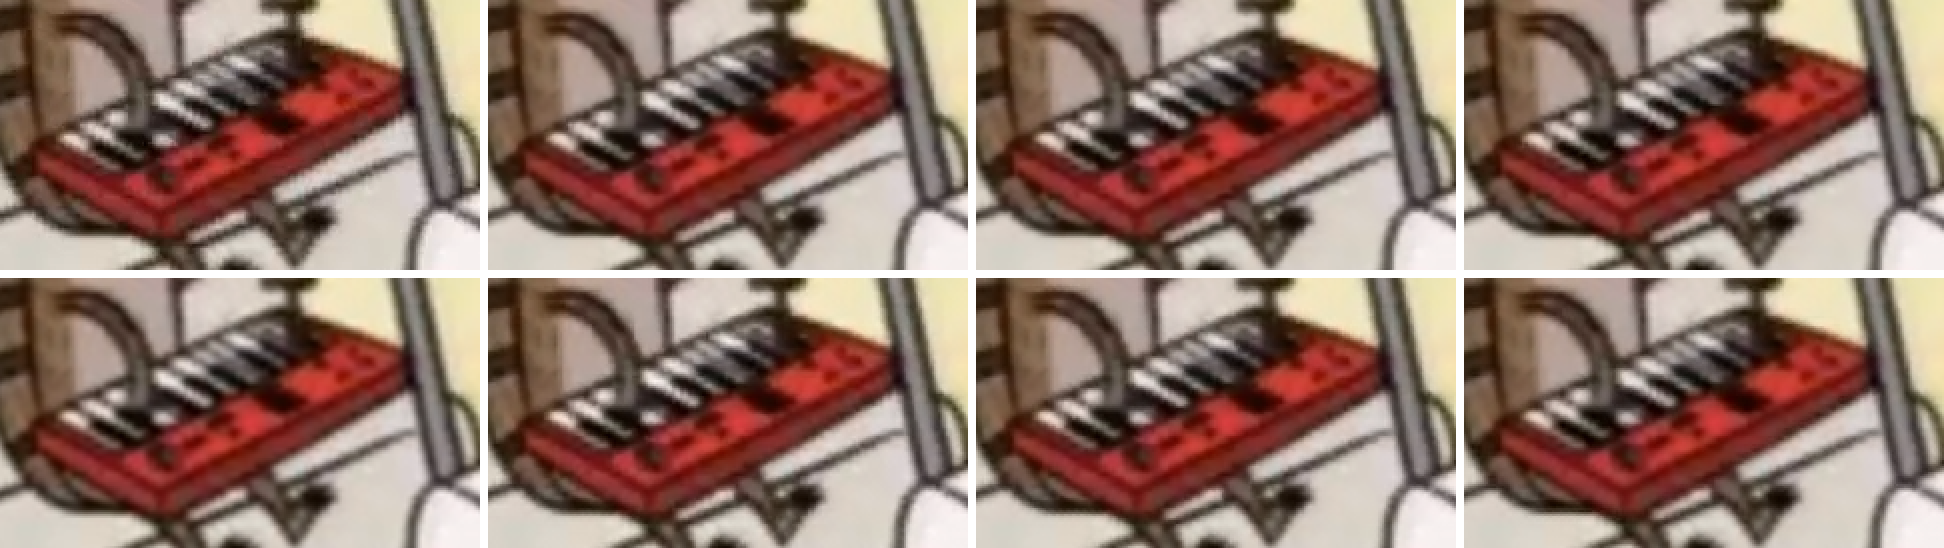

video: animation, 0.5mbps (0.072 bpp): slice QP 21, window at (360, 405)


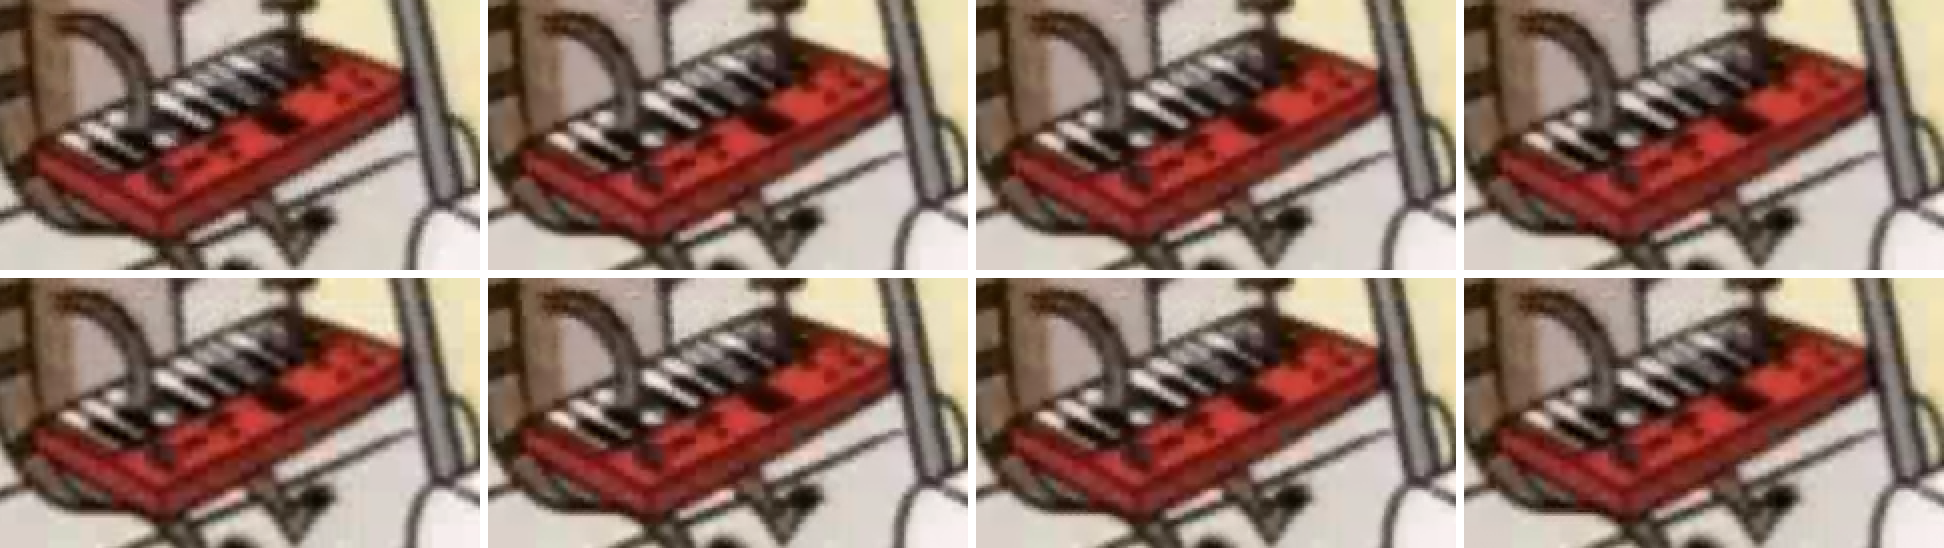

video: camera footage, default (0.460 bpp): slice QP 5, window at (180, 472)


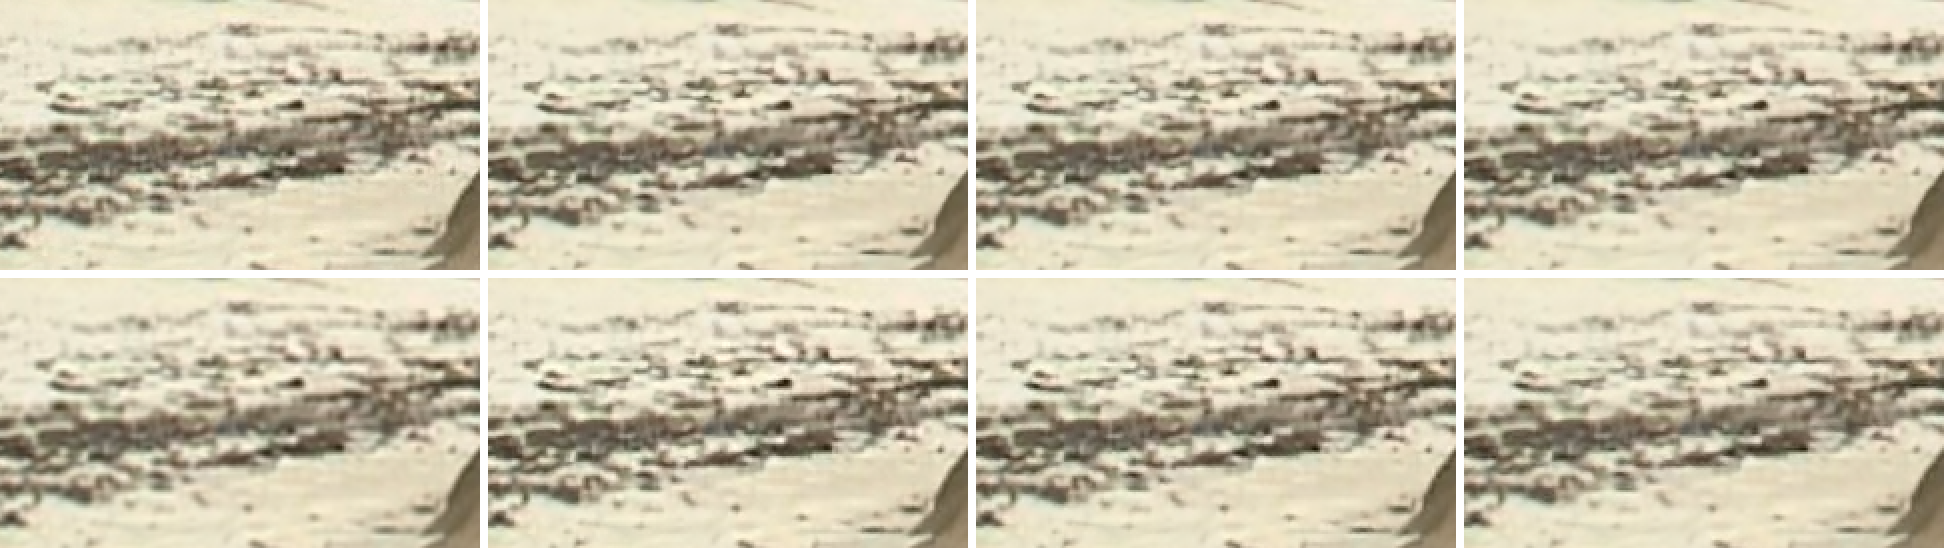

video: camera footage, 0.5mbps (0.087 bpp): slice QP 21, window at (180, 472)


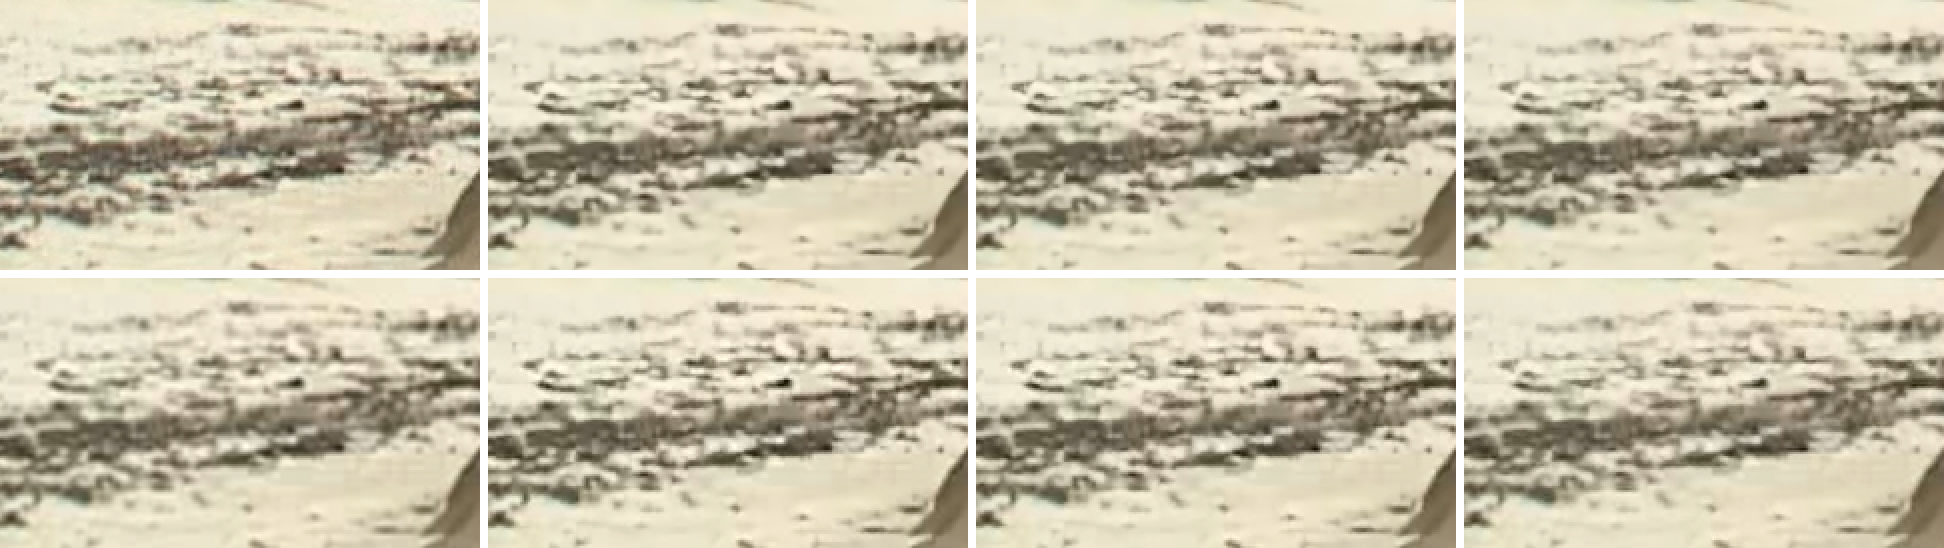

2416

In [9]:
FRAME_TOPICS = ("video: desktop and software use", "video: creative software", "video: pc games",
                "video: animation", "video: camera footage")
STREAMS = {"default": None, "0.5mbps": 0.5}    # the host's 0.46 bits a pixel, and a starved 0.5 Mbit/s
FRAME, CLIP_FRAMES, SIZE, WINDOW, HALO = 16, 24, (1280, 720), (135, 240), 4
SHOWN = {body: min(LAMBDAS, key=lambda loss: arm(body, loss, "lpips").mean()) for body in BODIES}
LAYOUT = [["truth", *[f"told 24x2, {loss}" for loss in ("SSIM loss", SHOWN["told 24x2"], "JND loss")]],
          ["bicubic", *[f"fast q24, {loss}" for loss in ("SSIM loss", SHOWN["fast q24"], "JND loss")]]]
FRAMES_DIR = SAMPLES / "frames"
FRAMES_DIR.mkdir(exist_ok=True)
clip_paths = {f"yt8m-videos/{path.parts[-2]}/{path.stem}": path for path in sources.files("yt8m-videos", "test")}
keys = sorted({s["key"] for s in manifest["splits"]["val"]["sources"]} & set(clip_paths))
topic_of = {s["key"]: s["group"] for s in manifest["splits"]["val"]["sources"]}


def to_uint8(x):
    return (x.clamp(0, 1) * 255).round().byte().permute(0, 2, 3, 1).cpu().numpy()


def first_clip(topic):
    """The first validation clip of a topic with CLIP_FRAMES frames of 1280x720: its key, those frames from its centre,
    and its frame rate."""
    width, height = SIZE
    for key in keys:
        if topic_of[key] != topic:
            continue
        frames, fps = sources.load_sequence(clip_paths[key])
        if len(frames) >= CLIP_FRAMES and frames.shape[1] >= height and frames.shape[2] >= width:
            top, left = (frames.shape[1] - height) // 4 * 2, (frames.shape[2] - width) // 4 * 2
            return key, frames[:CLIP_FRAMES, top:top + height, left:left + width], fps
    return None, None, None


def stream_frame(frames, fps, mbps):
    """(HR, LR, condition) of frame FRAME through the host's x264 line, at `mbps` (None: its default bits a pixel)."""
    bpp = degrade.STREAM_BPP if mbps is None else mbps * 1e6 / (SIZE[0] // SCALE * SIZE[1] // SCALE * fps)
    made = degrade.Degradation(scale=SCALE, bpp=bpp, fps=fps, filter="bicubic", deblock=False, encoder="x264")
    hr, lr, _, report = degrade.degrade(frames, made, with_frames=True)
    row = report[FRAME]
    condition = np.array([row["slice_qp"] / QP_MAX, row["deblocked"], row["type"] == "I"], np.float32)
    return hr[FRAME], lr[FRAME], condition, bpp


@torch.no_grad()
def upscale_frame(model, lr, condition):
    """A whole stream frame through a model, its edge pixels read again around it as the client does."""
    x = torch.from_numpy(np.pad(lr, ((HALO, HALO), (HALO, HALO), (0, 0)), mode="edge")).permute(2, 0, 1)[None]
    x = x.float().div(255).to(DEVICE)
    c = torch.from_numpy(condition)[None, :, None, None].to(DEVICE)
    out = model(x, c)[..., HALO * SCALE:-HALO * SCALE, HALO * SCALE:-HALO * SCALE]
    return to_uint8(out)[0]


def busiest_window(pairs):
    """The (top, left) of the WINDOW where pairs of pictures' luma differs most, summed over the pairs, on a grid of
    quarter windows."""
    luma = np.array([0.2126, 0.7152, 0.0722])
    diff = sum(np.abs(a.astype(np.float32) @ luma - b.astype(np.float32) @ luma) for a, b in pairs)
    diff = torch.from_numpy(diff.astype(np.float32))[None, None]
    sums = torch.nn.functional.avg_pool2d(diff, WINDOW, stride=(WINDOW[0] // 4, WINDOW[1] // 4))[0, 0].numpy()
    y, x = np.unravel_index(np.argmax(sums), sums.shape)
    return y * WINDOW[0] // 4, x * WINDOW[1] // 4


def grid(pictures, layout, path, zoom=2, gap=8):
    """Pictures placed as `layout` (rows of names), at `zoom` x with no smoothing, written as a PNG."""
    h, w = next(iter(pictures.values())).shape[:2]
    canvas = np.full((len(layout) * (h * zoom + gap) - gap, len(layout[0]) * (w * zoom + gap) - gap, 3), 255, np.uint8)
    for r, row in enumerate(layout):
        for c, name in enumerate(row):
            y, x = r * (h * zoom + gap), c * (w * zoom + gap)
            canvas[y:y + h * zoom, x:x + w * zoom] = pictures[name].repeat(zoom, 0).repeat(zoom, 1)
    Image.fromarray(canvas).save(path)
    return path


facts = {}
print("the mix shown: " + ", ".join(f"{body} {loss}" for body, loss in SHOWN.items()) + " (the better validation LPIPS)")
print("each grid: " + " | ".join(LAYOUT[0]) + "  /  " + " | ".join(LAYOUT[1]))
for topic in FRAME_TOPICS:
    key, frames, fps = first_clip(topic)
    if key is None:
        print(f"{topic}: no clip of 1280x720 and {CLIP_FRAMES} frames")
        continue
    for stream, mbps in STREAMS.items():
        hr, lr, condition, bpp = stream_frame(frames, fps, mbps)
        pictures = {"truth": hr, "bicubic": upscale_frame(Bicubic(), lr, condition)}
        for body in BODIES:
            for loss in LOSSES:
                pictures[f"{body}, {loss}"] = upscale_frame(trained[body, loss, 0], lr, condition)
        name = f"{topic.split(": ")[1].replace(' ', '_')}_{stream}"
        for label, picture in pictures.items():
            Image.fromarray(picture).save(FRAMES_DIR / f"{name}_{label.replace(', ', '_').replace(' ', '_')}.png")
        facts[name] = {"topic": topic, "clip": key, "frame": FRAME, "stream": stream, "bpp": round(bpp, 4),
                       "slice_qp": round(float(condition[0] * QP_MAX)), "deblocked": bool(condition[1]),
                       "intra": bool(condition[2]), "encoder": "x264"}
        top, left = busiest_window([(pictures[f"{body}, SSIM loss"], pictures[f"{body}, {SHOWN[body]}"]) for body in BODIES])
        window = {label: p[top:top + WINDOW[0], left:left + WINDOW[1]] for label, p in pictures.items()}
        print(f"{topic}, {stream} ({bpp:.3f} bpp): slice QP {facts[name]['slice_qp']}, window at ({left}, {top})")
        display(Show(filename=str(grid(window, LAYOUT, SAMPLES / f"frame_{name}.png"))))
(FRAMES_DIR / "frames.json").write_text(json.dumps(facts, indent=1), encoding="utf-8")

## 6. What kind of difference

Notebook 26's measures. On the validation patches, both seeds of each model: how much of the truth's fine detail it
keeps (the mean |Laplacian| of luma, over the truth's), its mean luma bias, and its luma error at the truth's strongest
edges (the top fifth of |Laplacian| in each patch) and everywhere else, in 8-bit levels. Then on the whole frames
above (seed 0), how much larger a step in luma is across a seam than anywhere else (1 is no seam): between LR pixels
(every 2 HR px), between the fast q24's 2×2 LR cells (every 4) and between the codec's macroblocks (every 16).

In [10]:
LAPLACE = torch.tensor([[0.0, 1, 0], [1, -4, 1], [0, 1, 0]], device=DEVICE)[None, None]


@torch.no_grad()
def character(model):
    """Detail kept, luma bias, and the error at edges and elsewhere, over the validation patches."""
    total = {"detail": 0.0, "truth_detail": 0.0, "bias": 0.0, "edges": 0.0, "flat": 0.0}
    for (lr, condition), hr in val_loader:
        lr, condition, hr = lr.to(DEVICE), condition.to(DEVICE), hr.to(DEVICE)
        truth = metrics.rgb_to_yuv(hr)[:, :1]
        picture = metrics.rgb_to_yuv(trim(model(lr, condition)).clamp(0, 1))[:, :1]
        lt, lp = (torch.nn.functional.conv2d(y, LAPLACE).abs() for y in (truth, picture))
        edges = (lt > lt.flatten(1).quantile(0.8, dim=1)[:, None, None, None]).float()
        error = (picture - truth).abs()[..., 1:-1, 1:-1]
        n = len(hr)
        total["detail"] += lp.mean().item() * n
        total["truth_detail"] += lt.mean().item() * n
        total["bias"] += 255 * (picture - truth).mean().item() * n
        total["edges"] += 255 * ((error * edges).sum() / edges.sum()).item() * n
        total["flat"] += 255 * ((error * (1 - edges)).sum() / (1 - edges).sum()).item() * n
    return {"detail": total["detail"] / total["truth_detail"], **{k: total[k] / len(val_set) for k in ("bias", "edges", "flat")}}


def seam(y, period):
    """The mean step in luma across seams every `period` px, over the mean step elsewhere, both axes."""
    out = []
    for a in (y, y.T):
        step = np.abs(np.diff(a, axis=1))
        on = np.arange(step.shape[1]) % period == period - 1
        out.append(step[:, on].mean() / step[:, ~on].mean())
    return float(np.mean(out))


luma = np.array([0.2126, 0.7152, 0.0722])
rows = {"bicubic": [Bicubic()], **{f"{body}, {loss}": [trained[body, loss, seed] for seed in SEEDS]
                                   for body in BODIES for loss in LOSSES}}
print(f"{'':<22}{'detail kept':>12}{'luma bias':>10}{'at edges':>10}{'elsewhere':>10}"
      f"{'seam 2 px':>11}{'seam 4 px':>11}{'seam 16 px':>12}")
for name in ["truth", *rows]:
    if name == "truth":
        cells = ["", "", "", ""]
    else:
        each = [character(model) for model in rows[name]]
        cells = [f"{np.mean([c[key] for c in each]):.3f}" for key in ("detail", "bias", "edges", "flat")]
    label = name.replace(", ", "_").replace(" ", "_")
    frames = [np.asarray(Image.open(FRAMES_DIR / f"{frame}_{label}.png")).astype(np.float64) @ luma for frame in facts]
    seams = [np.mean([seam(y, period) for y in frames]) for period in (2, 4, 16)]
    print(f"{name:<22}" + "".join(f"{cell:>{width}}" for cell, width in zip(cells, (12, 10, 10, 10)))
          + "".join(f"{s:{width}.3f}" for s, width in zip(seams, (11, 11, 12))))

                       detail kept luma bias  at edges elsewhere  seam 2 px  seam 4 px  seam 16 px
truth                                                                 1.078      1.125       1.318
bicubic                      0.348    -0.076    23.391     3.141      0.951      1.066       1.303
told 24x2, SSIM loss         0.598    -0.111    16.963     2.830      1.104      1.146       1.393
told 24x2, mix 0.1           0.589     0.070    16.679     2.781      1.128      1.164       1.405
told 24x2, mix 0.3           0.581     0.130    16.851     2.794      1.129      1.168       1.419
told 24x2, mix 1             0.554     0.304    17.228     2.806      1.144      1.183       1.447
told 24x2, JND loss          0.540     0.696    18.645     3.014      1.121      1.164       1.415
fast q24, SSIM loss          0.528    -0.070    19.769     3.096      1.180      1.285       1.456
fast q24, mix 0.1            0.524    -0.032    19.643     3.009      1.126      1.229       1.417
fast q24, 

## 7. What it says

- **Mix 0.1 is the only mix that costs no SSIM-Y, and it gains little else.** For the told 24×2 it is level with
  the SSIM loss on SSIM-Y (0.8920 against 0.8917, seeds 0.0003 and 0.0004 apart), LPIPS (0.1516 against 0.1515) and
  JND (4.594 against 4.595), and above it on luma (+0.17 dB, seeds 0.007 and 0.057 dB apart) and GMSD (0.0753 against
  0.0759, seeds 0.0004 apart). Patch by patch it is better on 60% by SSIM-Y, 74% by luma dB, 62% by GMSD and 53% by
  LPIPS. For the fast q24 it is 0.0005 SSIM-Y under the SSIM loss (its seeds 0.0009 apart), +0.13 dB of luma, and
  LPIPS 0.1656 against 0.1663, inside its seeds' 0.0011: better by LPIPS on 55% of the patches.
- **More of the JND term costs more.** At λ = 0.3 and 1 the told 24×2 gives up 0.0018 and 0.0045 SSIM-Y and the fast
  q24 0.0016 and 0.0046, and at λ = 1 both lose LPIPS too (0.1547 against 0.1515, 0.1697 against 0.1663; better on
  40% and 39% of the patches). Every mix keeps a luma gain of +0.08 to +0.17 dB over the SSIM loss, more than the JND
  loss alone, which loses 0.17 to 0.41 dB.
- **The scales**: on the SSIM-loss runs the JND term's gradient is 3.2 to 3.7 times the SSIM loss's (the two pull
  equally at λ = 0.27 and 0.31), so λ = 0.1 gives it about a third of the SSIM loss's pull, 0.3 about the same and 1
  over three times.
- **What the mixes change.** Mix 0.1 centres the brightness (luma bias +0.07 and −0.03 levels, against −0.11 and
  −0.07 under the SSIM loss) and misses a little less at the strongest edges for the told 24×2 (16.7 against 17.0
  levels). On the fast q24 it takes part of the grid away: on the whole frames (seed 0) the step across its 2×2 cells
  is 1.23 times the step elsewhere against 1.29 under the SSIM loss (1.13 in the truth), and mix 1 takes more (1.17)
  than the JND loss alone (1.20). On the told 24×2 every mix leaves a little more of a grid between LR pixels than the
  SSIM loss (1.13 to 1.14 against 1.10; 1.08 in the truth).
- **None of it is a clear win**: no mix beats the SSIM loss by more than its seeds land apart on SSIM-Y or LPIPS, for
  either body. Nothing is exported.

**Not measured:** what people prefer. The frames are written to `data/samples/27_mix/one_set/frames/`; the windows
where the SSIM-loss run and the mix differ most, looked at in passing, show no difference that is easy to see at 2×.